In [1]:
META = {
    "id": "S0004",
    "title": "Multi-horizon trend ensemble long-flat, 5 coins, spot",
    "status": "viable",  # testing | viable | rejected
    "hypotheses": ["hypotheses/H0012_n_day_high_anchoring_and_donchian_breakouts.ipynb",
                   "hypotheses/H0002_vol_scaled_time_series_momentum_5_coins.ipynb"],
    "result": "5-coin EW net (spot) WF OOS Sharpe 1.41 vs BH 1.09, CAGR 35.9%, maxDD -27%, MC95 DD -39% full path (1-year MC95 -26.0%: marginal fail of the -25% paper-trade DD limit), BTC alone 1.53; corr 0.96 with S0002 -> replacement/blend candidate, not additive (2022+ Sharpe 0.96 vs S0002 1.05; 50/50 blend 1.03); ETH re-optimized-grid 2nd-half perm p 0.073",
}

# S0004 - Multi-horizon trend ensemble, long/flat, 5 coins, spot
**Based on:** H0012 (Donchian state ensemble: Sharpe 1.11 full, 0.73 vs 0.63 for H0002 since 2022, turnover 4.3 vs 18.8 units/yr) and H0002 (vol-scaled TSMOM long/flat).

**Idea:** replace S0002's per-fold lookback choice (L jumps between 14 and 56) with a fixed ensemble of horizons: a Donchian-state ensemble (N = 20/55/120/250 or 10/20/55/120) mixed with a TSMOM sign ensemble (L = 14/28/56), vol-sized to a daily-vol target, with S0002's rebalance band. Run on OKX spot BTC ETH XRP LTC SOL, equal-weight, long/flat <= 1x.

## How it works - deployment report

**Idea (Moskowitz, Ooi & Pedersen 2012 time-series momentum; Donchian / turtle channel breakouts; tested in H0002 and H0012).** Own a coin only while several trend measures at different horizons agree it is going up, size it by its volatility, and sit in cash otherwise. S0002 had to pick one lookback per coin and the pick jumped around between folds; here the horizons are fixed in an ensemble, so there is nothing fragile to re-tune.

**Exact rules (once per day, per coin, BTC ETH XRP LTC SOL).**
1. At the 00:00 UTC daily close, take the last closed daily candle. `sigma` = std of the last 60 daily log returns.
2. Trend score `ts` = share of the three lookbacks L = 14, 28, 56 days for which `close / close L days ago - 1 > 0` (0, 1/3, 2/3 or 1).
3. Donchian score `don` = average over N in NS of a channel state: switch to 1 when close exceeds the prior N-day high, to 0 when it falls below the prior N/2-day low, otherwise keep the last state.
4. `P = alpha * don + (1 - alpha) * ts`; target weight `w = P * min(tv / sigma, 1)`. With band 0.1 only resize if `w` moved by more than 0.1 (entries and exits always execute).
5. Coin notional = equity / 5 * w (long only, spot, never above 1x gross).
6. Parameters (alpha in {0, 0.5, 1}, NS in {20/55/120/250, 10/20/55/120}, tv in {0.02, 0.03}, band in {0, 0.1}) are re-chosen per coin on the most recent ~30% of history, about every 10 months. In walk-forward the optimizer picked **alpha = 0 (pure 14/28/56 trend ensemble), tv 0.02, band 0.1 in 6 of 7 BTC folds**; the Donchian leg is rarely chosen. Live choice (data to 2025-09-30, last pre-holdout bar): BTC, XRP, LTC alpha 0 (NS 20/55/120/250) tv 0.02 band 0.1; ETH alpha 0.5 NS 10/20/55/120 tv 0.02 band 0.1; SOL alpha 1 NS 10/20/55/120 tv 0.02 band 0.1. Target sleeve weights on 2025-09-30: BTC 0.33, ETH 0.16, XRP 0, LTC 0, SOL 0.12.

**Instrument / timing.** OKX spot `*-USDT`, daily bar close 00:00 UTC, rebalance within minutes of the close with aggressive limit/market orders. About 10-14 new entries per coin per year plus small resizes (turnover 13-21x notional per coin per year).

**Expected performance (net walk-forward OOS 2020-05 -> 2025-09 (portfolio from 2020-08), OKX spot costs 0.10% taker + spread + slippage).**

| | 5-coin portfolio | EW buy & hold | BTC alone | BTC buy & hold |
|---|---|---|---|---|
| Sharpe | **1.41** | 1.09 | 1.53 | 1.12 |
| CAGR | 35.9% | 69.4% | 46.2% | 63.0% |
| Max drawdown | **-26.9%** | -79.9% | -30.0% | -75.6% |
| Ann. vol | 24% | 74% | 27% | 59% |
| Monte Carlo 95th-pct max DD (full path) | **-39%** | | -42% | |

Paper-trade gate (net WF OOS Sharpe >= 1.2, CAGR >= 15%, 1-year MC95 max DD no worse than -25%) on the saved portfolio stream: Sharpe 1.41 (pass), CAGR 35.9% (pass), 1-year MC95 max DD **-26.0% (marginal fail, limit -25%)**.

Average gross exposure is only 29% of equity (tv 0.02 is a lower risk target than S0002's 0.03), so it lags buy & hold on raw return in bull runs and wins by avoiding bear drawdowns. 2022+: Sharpe 0.96 vs 0.67 for EW buy & hold; 2022: -1.43 Sharpe (loses, like everything long-only) with max DD -21.5%.

**Costs.** Spot trading costs ~2.3%/yr on BTC (2.0%/yr on the portfolio), no funding. On perps with real funding the portfolio Sharpe drops from 1.41 to 1.32 (funding ~2.2%/yr more).

**Leverage.** **1x.** Leverage sweep on BTC (perp costs): 1.5x CAGR 53% / DD -48%, 2x DD -59%, 5x DD -92%, 10x+ liquidated. Sharpe does not rise with leverage.

**When it fails.** Whipsaw/chop (BTC fold 2024-12..2025-09: -2% net while buy & hold was +20%; 2022 bear: -21.5% DD), slow re-entry after V-shaped recoveries, LTC (net WF Sharpe 0.30 vs 0.63 buy & hold; SOL and LTC walk-forward efficiency 0.23 and 0.18) and weak recent years (2025+ portfolio Sharpe 0.54 vs 0.79 for buy & hold).

**Relation to S0002 (important).** Portfolio net OOS correlation with S0002 is **0.96** (0.95 since 2022). It is the same trend factor with a more stable lookback choice, not a new return stream. It is a REPLACEMENT candidate for S0002's trend sleeve, not an additional strategy. 50/50 S0002+S0004: Sharpe 1.44 full / 1.03 since 2022, max DD -33%, MC 95% DD -44% (S0002 alone -50%, S0004 alone -39%).

**Live data / feeds needed.** OKX public websocket `wss://ws.okx.com:8443/ws/v5/business`, channel `candle1Dutc` for the five `-USDT` pairs (act on `confirm = "1"`); REST warm-up `GET /api/v5/market/candles?instId=BTC-USDT&bar=1Dutc` with >= 300 days of history (N = 250 + 60-day vol). Private `account` and `orders` channels for fills; lot size from `GET /api/v5/public/instruments?instType=SPOT`; skip orders smaller than ~2% of a sleeve.

**Verdict: VIABLE as a replacement for / blend with S0002, NOT an extra deployable.** Passes every checklist item, and BTC alone is much better than S0002's BTC (net Sharpe 1.53 vs 1.33), but the 5-coin portfolio is statistically the same as S0002 (Sharpe 1.41 vs 1.44; post-2022 0.96 vs 1.05; 2025+ 0.54 vs 0.55). Its 1-year MC95 max DD (-26.0%) just misses the -25% limit. Preferred use: deploy the 50/50 blend or pick one; do not stack both.

In [2]:
import numpy as np, pandas as pd
from pathlib import Path
from types import SimpleNamespace
from qr import q, ohlcv, okx_funding, run, metrics, CostModel, leverage_sweep
from qr.optimize import grid_search, best_params, deflated_sharpe
from qr.walkforward import walk_forward
from qr.montecarlo import monte_carlo
from qr.permutation import permutation_test
from qr.registry import save_oos, RESULTS_DIR
from qr.plots import plot_heatmap, plot_leverage, plot_result, plot_corr
import warnings; warnings.filterwarnings('ignore', message='obj.round has no effect')

## Data
OKX **spot** daily candles (`1Dutc`) for signals and returns (spot history 2018-01, SOL 2020-10). Primary costs: `CostModel.okx_spot()` (taker 0.10%, spread/slippage, no funding). Comparison row: OKX perp costs with each coin's real funding.

In [3]:
COINS = ['BTC', 'ETH', 'XRP', 'LTC', 'SOL']
DATA = {c: ohlcv(c, '1d') for c in COINS}
SPOT = CostModel.okx_spot()
PERP_BY = {c: CostModel.okx_perp(funding=okx_funding(c)) for c in COINS}
df = DATA['BTC']
pd.DataFrame({c: {'first': d.index[0].date(), 'last': d.index[-1].date(), 'bars': len(d)} for c, d in DATA.items()}).T

,first,last,bars
BTC,2018-01-11,2025-09-30,2820
ETH,2018-01-11,2025-09-30,2820
XRP,2018-01-11,2025-09-30,2820
LTC,2018-01-11,2025-09-30,2820
SOL,2020-10-01,2025-09-30,1826


## Signal
Per bar, decided at the daily close (past data only):
- `sigma` = std of 60 daily log returns.
- `don_N`: `hi = close.shift(1).rolling(N).max()`, `lo = close.shift(1).rolling(N//2).min()`; state = 1 if close > hi, 0 if close < lo, otherwise the previous state (H0012 `donchian_state`); 0 in warm-up. `don` = mean of `don_N` over N in NS.
- `ts` = mean over L in (14, 28, 56) of `1[close / close.shift(L) - 1 > 0]`.
- `P = alpha * don + (1 - alpha) * ts` in [0, 1]; `pos = P * min(tv / sigma, 1)`.
- S0002 rebalance band: resize only when `|new - old| > band`; entries/exits always execute. Forward loop over past targets.

The engine shifts the signal one bar (decide at close t, hold during day t+1).

In [4]:
TS_LS = (14, 28, 56)

def donchian_state(close, N):
    hi = close.shift(1).rolling(N, min_periods=N).max()
    lo = close.shift(1).rolling(N // 2, min_periods=N // 2).min()
    st = pd.Series(np.where(close > hi, 1.0, np.where(close < lo, 0.0, np.nan)), index=close.index)
    return st.ffill().fillna(0.0).where(hi.notna(), 0.0)      # 0 in warm-up

def signal(df, p):
    close = df['close']
    sigma = np.log(close).diff().rolling(60).std()
    don = pd.concat([donchian_state(close, N) for N in p['NS']], axis=1).mean(axis=1)
    ts = pd.concat([(close / close.shift(L) - 1 > 0).astype(float) for L in TS_LS], axis=1).mean(axis=1)
    P = p['alpha'] * don + (1 - p['alpha']) * ts
    size = (p['tv'] / sigma).clip(upper=1.0)
    tgt = (P * size).where(sigma.notna(), 0.0).clip(0, 1).fillna(0).values
    band = p.get('band', 0)
    if band <= 0:
        return pd.Series(tgt, index=df.index)
    out, cur = np.empty_like(tgt), 0.0
    for i, t in enumerate(tgt):           # past targets only
        if (t == 0) != (cur == 0) or abs(t - cur) > band:
            cur = t
        out[i] = cur
    return pd.Series(out, index=df.index)

def entries_per_year(pos):
    """Flat -> long transitions per year (resizes are not counted as trades)."""
    p = pos.fillna(0)
    return float(((p > 0) & (p.shift(1).fillna(0) == 0)).sum() / (len(p) / 365.25))

In [5]:
# Lookahead check: signal on truncated history must equal the full-history signal at every cut.
_p = {'alpha': 0.5, 'NS': (20, 55, 120, 250), 'tv': 0.03, 'band': 0.1}
full = signal(df, _p)
for k in [300, 800, 1500, 2500, len(df) - 1]:
    assert np.allclose(signal(df.iloc[:k], _p).values, full.iloc[:k].values), k
assert signal(df, _p).between(0, 1).all()
print('truncation test passed: no lookahead; range [0,1]')

truncation test passed: no lookahead; range [0,1]


## Stage 3 - Baseline backtest (no costs)
H0012's own spec: alpha 1 (pure Donchian ensemble), NS (20, 55, 120, 250), tv 0.02, band 0. BTC, full history.

,strategy,buy_hold
total_return,6.851635,7.582
cagr,0.305919,0.321
ann_vol,0.230732,0.659
sharpe,1.271532,0.757
sortino,1.573498,1.007
max_dd,-0.296255,-0.774
calmar,1.032623,0.415
bars,2820,2820.000
trades,26,NaN
win_rate,0.307692,NaN


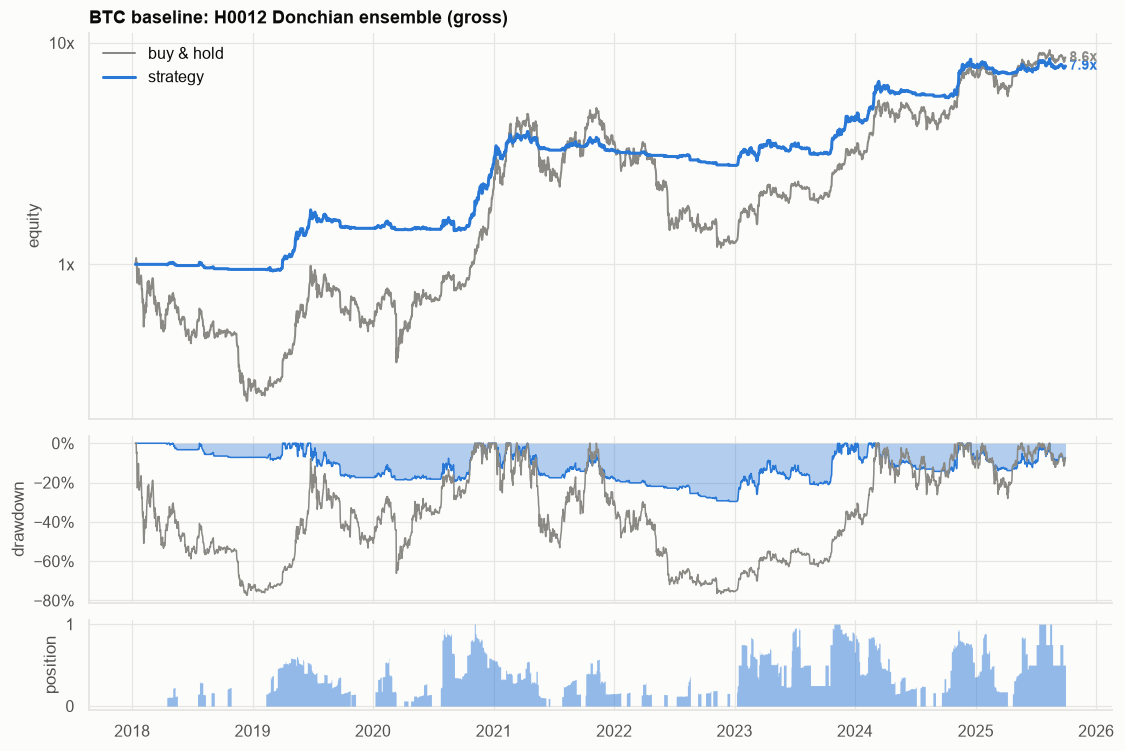

In [6]:
PARAMS = {'alpha': 1.0, 'NS': (20, 55, 120, 250), 'tv': 0.02, 'band': 0.0}
base = run(df, signal, PARAMS)
base.plot('BTC baseline: H0012 Donchian ensemble (gross)');
s = base.summary(); s.loc['entries_per_year', 'strategy'] = entries_per_year(base.position); s.round(3)

## Stage 4 - Parameter optimization (in-sample only, BTC first half)
GRID: alpha {0, 0.5, 1} x NS {(20,55,120,250), (10,20,55,120)} x tv {0.02, 0.03} x band {0, 0.1} = 24 combos (alpha = 0 rows duplicate across NS -> 20 unique). Plateau-smoothed Sharpe picks the winner; DSR deflates for 24 trials (the duplicates make this slightly conservative).

In [7]:
GRID = {'alpha': [0.0, 0.5, 1.0], 'NS': [(20, 55, 120, 250), (10, 20, 55, 120)], 'tv': [0.02, 0.03], 'band': [0.0, 0.1]}
IS_END = df.index[len(df) // 2]
table = grid_search(df.loc[:IS_END], signal, GRID)
BEST = best_params(table, GRID)
print('IS window:', df.index[0].date(), '->', IS_END.date(), '| best plateau params:', BEST)
table[['alpha', 'NS', 'tv', 'band', 'sharpe', 'cagr', 'max_dd', 'turnover_per_year', 'score', 'smoothed']].head(12).round(3)

IS window: 2018-01-11 -> 2021-11-21 | best plateau params: {'alpha': 0.0, 'NS': (20, 55, 120, 250), 'tv': 0.02, 'band': 0.1}


,alpha,NS,tv,band,sharpe,cagr,max_dd,turnover_per_year,score,smoothed
0,0.0,"(20, 55, 120, 250)",0.02,0.1,1.654,0.543,-0.329,15.536,1.654,1.601
1,0.0,"(10, 20, 55, 120)",0.02,0.1,1.654,0.543,-0.329,15.536,1.654,1.601
2,0.0,"(20, 55, 120, 250)",0.02,0.0,1.635,0.533,-0.329,16.832,1.635,1.601
3,0.0,"(10, 20, 55, 120)",0.02,0.0,1.635,0.533,-0.329,16.832,1.635,1.601
4,0.0,"(20, 55, 120, 250)",0.03,0.1,1.612,0.748,-0.420,22.083,1.612,1.601
5,0.0,"(10, 20, 55, 120)",0.03,0.1,1.612,0.748,-0.420,22.083,1.612,1.601
6,0.0,"(20, 55, 120, 250)",0.03,0.0,1.597,0.732,-0.417,22.800,1.597,1.601
7,0.0,"(10, 20, 55, 120)",0.03,0.0,1.597,0.732,-0.417,22.800,1.597,1.601
8,0.5,"(10, 20, 55, 120)",0.02,0.0,1.624,0.477,-0.243,12.076,1.624,1.565
9,0.5,"(10, 20, 55, 120)",0.02,0.1,1.617,0.465,-0.243,8.946,1.617,1.565


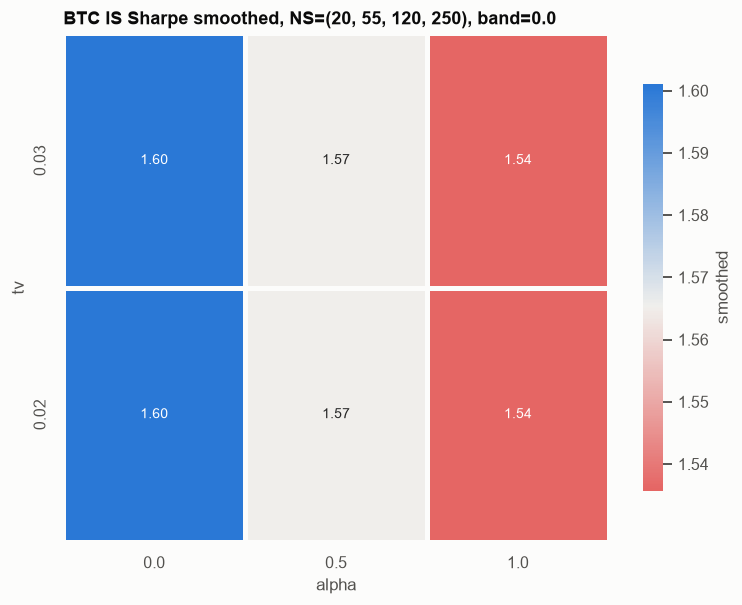

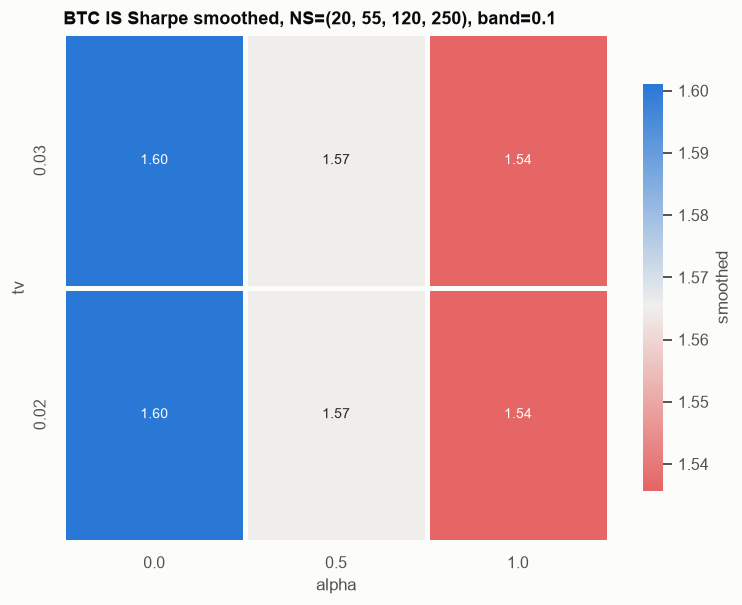

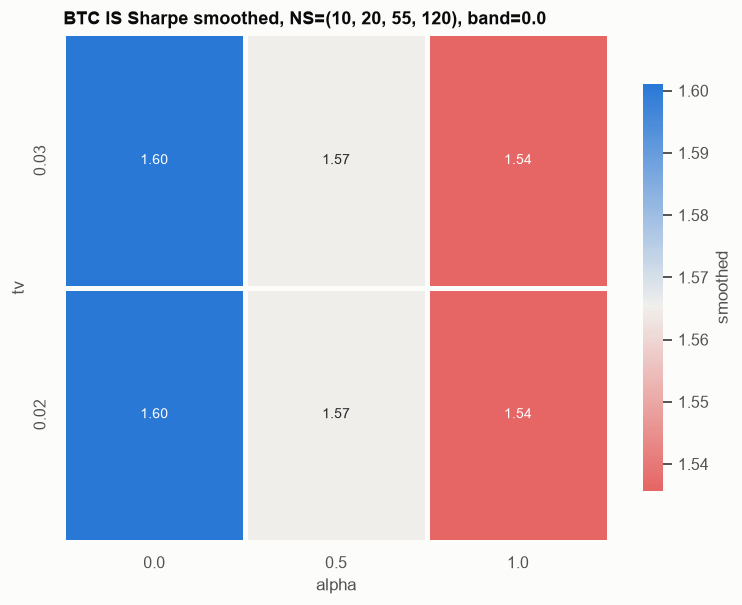

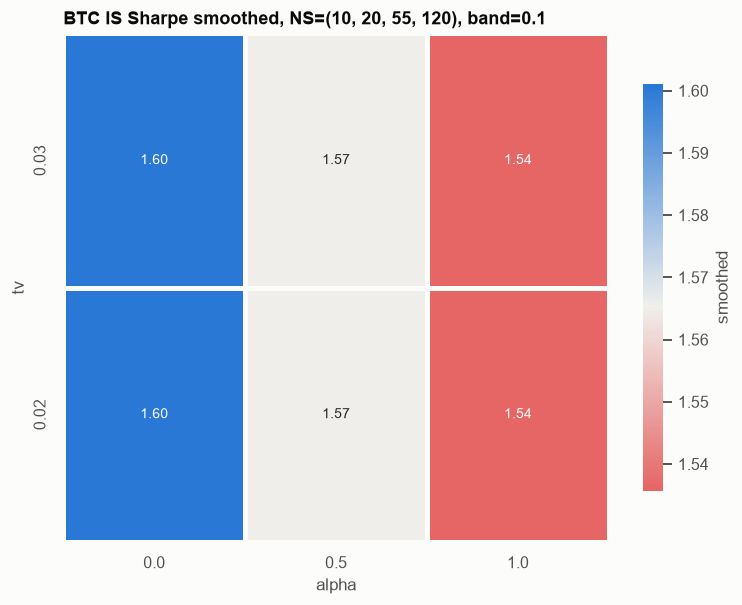

In [8]:
for ns in GRID['NS']:
    for band in GRID['band']:
        t = table[(table.NS == ns) & (table.band == band)]
        plot_heatmap(t, x='alpha', y='tv', value='smoothed', title=f'BTC IS Sharpe smoothed, NS={ns}, band={band}');

In [9]:
is_best = run(df.loc[:IS_END], signal, BEST)
deflated_sharpe(is_best.returns, table['sharpe'])

{'sharpe_ann': np.float64(1.6541227726161694),
 'sr0_ann': np.float64(0.13422056487846215),
 'n_trials': 24,
 'dsr': np.float64(0.9992534434922727)}

## Stage 5 - Walk-forward out-of-sample (BTC)
10 slices; optimize on 3, trade the next, slide 10%. First 3 slices (2018-01 -> 2020-08) never traded OOS. Gross, then net with spot costs.

,fold,train_start,train_end,test_start,test_end,alpha,NS,tv,band,is_sharpe,oos_sharpe,oos_return,bh_return
0,1,2018-01-11 00:00:00+00:00,2020-05-05 00:00:00+00:00,2020-05-06 00:00:00+00:00,2021-02-11 00:00:00+00:00,1.0,"(10, 20, 55, 120)",0.02,0.1,1.126,3.413,1.435,4.245
1,2,2018-10-20 00:00:00+00:00,2021-02-11 00:00:00+00:00,2021-02-12 00:00:00+00:00,2021-11-20 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,2.407,1.205,0.225,0.262
2,3,2019-07-29 00:00:00+00:00,2021-11-20 00:00:00+00:00,2021-11-21 00:00:00+00:00,2022-08-29 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,2.120,-1.718,-0.191,-0.654
3,4,2020-05-06 00:00:00+00:00,2022-08-29 00:00:00+00:00,2022-08-30 00:00:00+00:00,2023-06-07 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.856,1.494,0.324,0.330
4,5,2021-02-12 00:00:00+00:00,2023-06-07 00:00:00+00:00,2023-06-08 00:00:00+00:00,2024-03-15 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,0.614,3.363,1.289,1.623
5,6,2021-11-21 00:00:00+00:00,2024-03-15 00:00:00+00:00,2024-03-16 00:00:00+00:00,2024-12-22 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.590,0.985,0.204,0.457
6,7,2022-08-30 00:00:00+00:00,2024-12-22 00:00:00+00:00,2024-12-23 00:00:00+00:00,2025-09-30 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.959,0.137,0.006,0.202


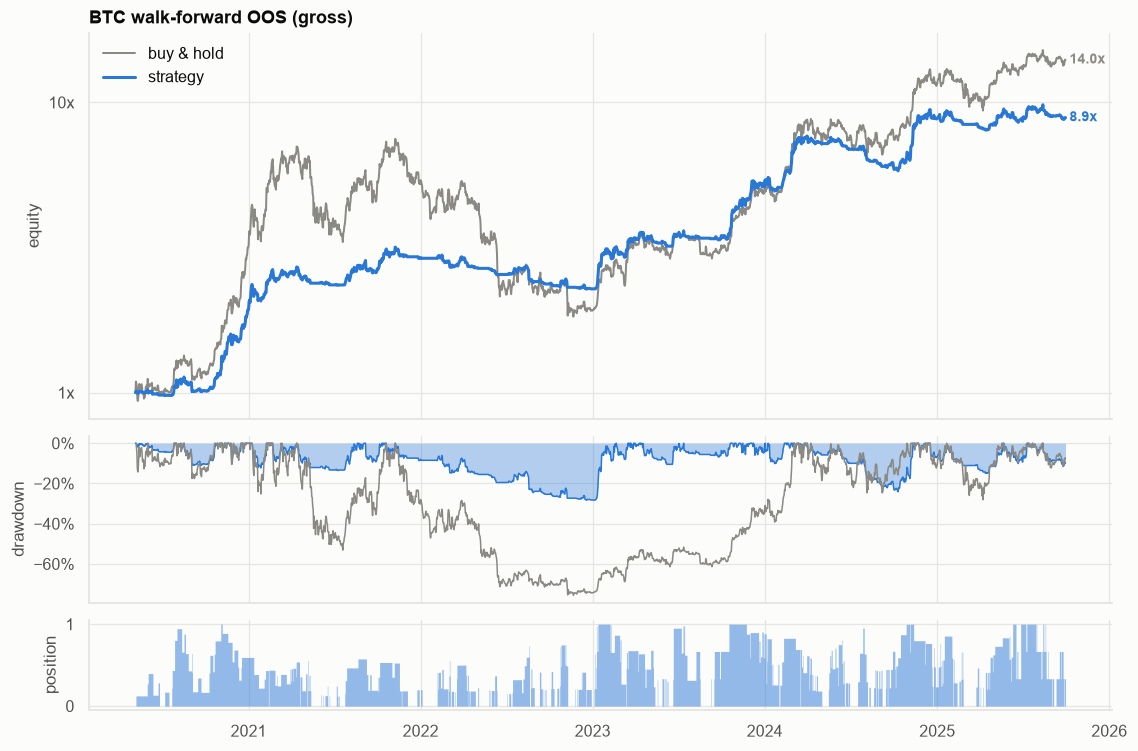

In [10]:
wf = walk_forward(df, signal, GRID, n_chunks=10, train_chunks=3)
wf.plot('BTC walk-forward OOS (gross)');
wf.folds.round(3)

In [11]:
pd.DataFrame({'wf_oos': wf.metrics, 'buy_hold': wf.bh_metrics}).round(3)

,wf_oos,buy_hold
total_return,7.859,13.006
cagr,0.497,0.630
ann_vol,0.272,0.590
sharpe,1.618,1.122
sortino,2.257,1.605
max_dd,-0.283,-0.756
calmar,1.756,0.833
bars,1974.000,1974.000
trades,78.000,NaN
win_rate,0.308,NaN


## Stage 6 - Monte Carlo (5000 block-bootstrap resamples of OOS returns)
BTC first (gross here, net spot below); portfolio MC in the portfolio section.

,value
"VaR 95% (loss, <0 = gain)",-1.660
CVaR 95%,-1.066
VaR 99%,-0.694
CVaR 99%,-0.343
median total return,7.782
mean total return,11.171
P(loss),0.001
median max DD,-0.261
95th pct max DD,-0.401
99th pct max DD,-0.490


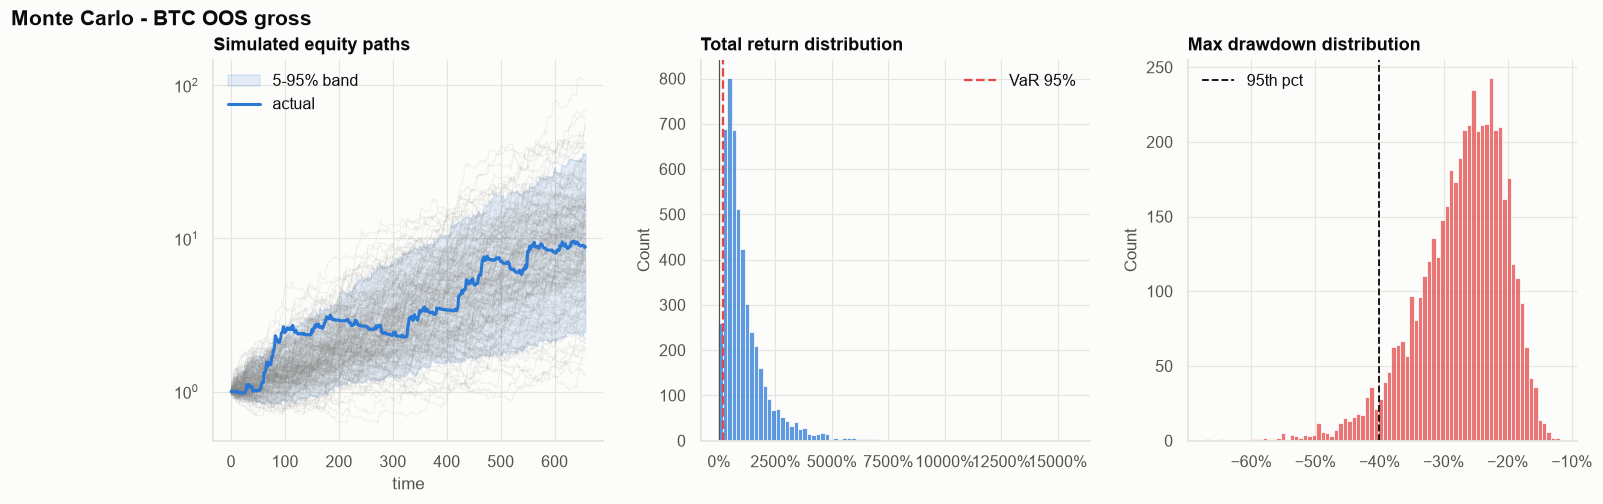

In [12]:
mc = monte_carlo(wf.returns, n=5000, method='block', block=20)
mc.plot('Monte Carlo - BTC OOS gross');
mc.table.round(3)

## Stage 7 - Permutation test
(a) Fixed best params, 2000 shuffled markets, BTC in-sample (gross) - the standard test. (b) Stricter data-mining test: `param_grid=GRID` re-optimized on every permutation, **net spot costs**, n=300, BTC and ETH, on the IS half **and the second half** (S0002 failed its second half).

real sharpe                  1.6541
perm mean sharpe             0.6657
perm 95th pct sharpe         1.1926
p_value                      0.0020
EV total return (null)       0.8621
n_permutations            2000.0000
dtype: float64

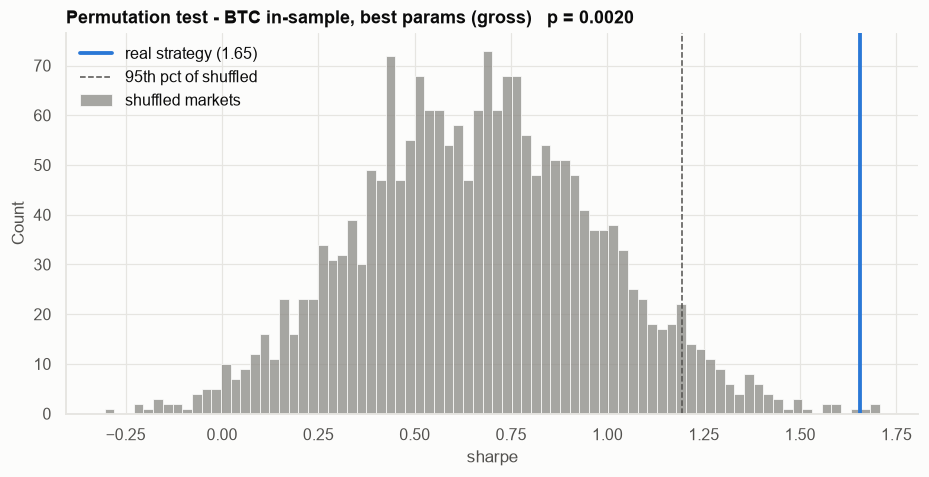

In [13]:
perm = permutation_test(df.loc[:IS_END], signal, BEST, n=2000, n_jobs=-1)
perm.plot('Permutation test - BTC in-sample, best params (gross)');
perm.summary().round(4)

In [14]:
import time
PERM = {}
for c in ['BTC', 'ETH']:
    d = DATA[c]; mid = d.index[len(d) // 2]
    for name, sub_ in [('IS first half', d.loc[:mid]), ('second half', d.loc[mid:])]:
        t0 = time.time()
        r_ = permutation_test(sub_, signal, param_grid=GRID, n=300, costs=SPOT, n_jobs=-1)
        PERM[(c, name)] = {'real_sharpe': r_.real, 'p_value': r_.p_value, 'n': 300, 'secs': round(time.time() - t0)}
pd.DataFrame(PERM).T

real_sharpe   p_value      n  secs
BTC IS first half     1.591732  0.009967  300.0  37.0
    second half       1.096053  0.023256  300.0  45.0
ETH IS first half     1.685902  0.006645  300.0  33.0
    second half       0.745570  0.073090  300.0  39.0

## Stage 8 - Reality: spot costs and leverage (BTC)
Primary: OKX spot (taker 0.10%/side + spread + slippage, no funding). Leverage sweep uses perp costs with real funding (spot cannot be levered).

,gross,net_spot,buy_hold
total_return,7.859,6.797,13.006
cagr,0.497,0.462,0.630
ann_vol,0.272,0.272,0.590
sharpe,1.618,1.531,1.122
sortino,2.257,2.174,1.605
max_dd,-0.283,-0.300,-0.756
calmar,1.756,1.539,0.833
bars,1974.000,1974.000,1974.000
trades,78.000,78.000,NaN
win_rate,0.308,0.282,NaN


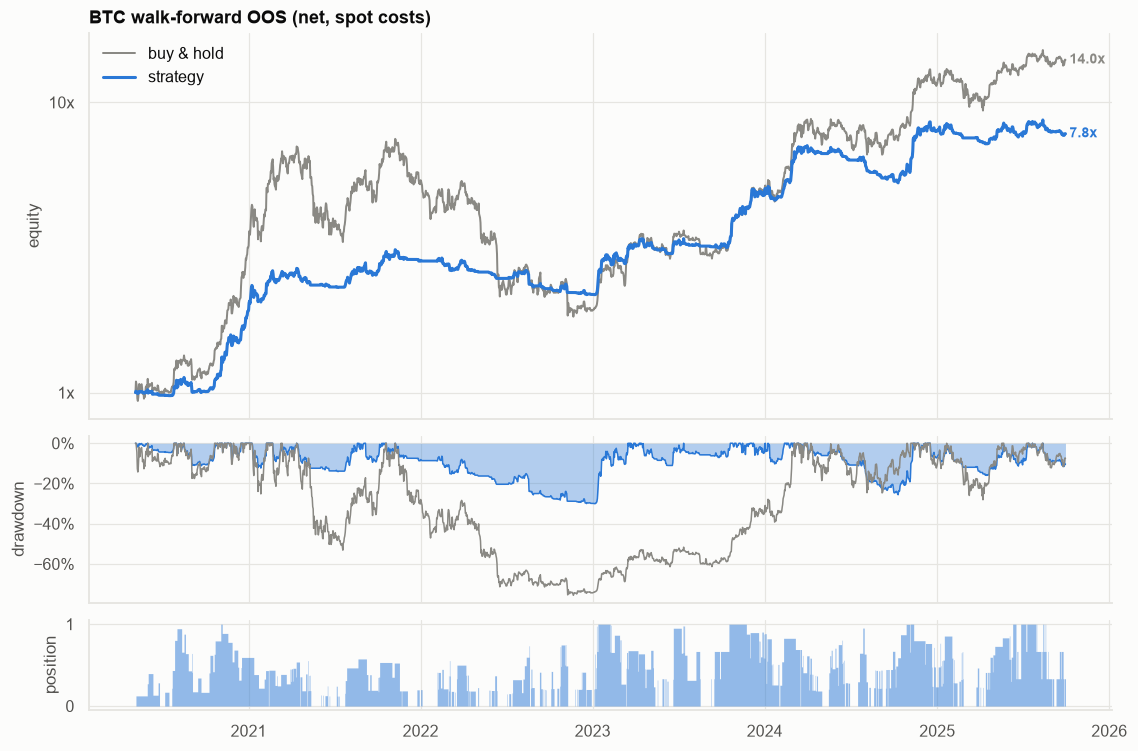

In [15]:
wf_net = walk_forward(df, signal, GRID, n_chunks=10, train_chunks=3, costs=SPOT)
wf_net.plot('BTC walk-forward OOS (net, spot costs)');
cmp = pd.DataFrame({'gross': wf.metrics, 'net_spot': wf_net.metrics, 'buy_hold': wf_net.bh_metrics})
cmp.loc['entries_per_year'] = [entries_per_year(wf.position), entries_per_year(wf_net.position), np.nan]
cmp.round(3)

In [16]:
wf_net.folds.round(3)

,fold,train_start,train_end,test_start,test_end,alpha,NS,tv,band,is_sharpe,oos_sharpe,oos_return,bh_return
0,1,2018-01-11 00:00:00+00:00,2020-05-05 00:00:00+00:00,2020-05-06 00:00:00+00:00,2021-02-11 00:00:00+00:00,1.0,"(10, 20, 55, 120)",0.02,0.1,1.092,3.381,1.414,4.245
1,2,2018-10-20 00:00:00+00:00,2021-02-11 00:00:00+00:00,2021-02-12 00:00:00+00:00,2021-11-20 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,2.352,1.140,0.210,0.262
2,3,2019-07-29 00:00:00+00:00,2021-11-20 00:00:00+00:00,2021-11-21 00:00:00+00:00,2022-08-29 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,2.062,-1.836,-0.202,-0.654
3,4,2020-05-06 00:00:00+00:00,2022-08-29 00:00:00+00:00,2022-08-30 00:00:00+00:00,2023-06-07 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.796,1.382,0.294,0.330
4,5,2021-02-12 00:00:00+00:00,2023-06-07 00:00:00+00:00,2023-06-08 00:00:00+00:00,2024-03-15 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,0.520,3.301,1.251,1.623
5,6,2021-11-21 00:00:00+00:00,2024-03-15 00:00:00+00:00,2024-03-16 00:00:00+00:00,2024-12-22 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.503,0.876,0.176,0.457
6,7,2022-08-30 00:00:00+00:00,2024-12-22 00:00:00+00:00,2024-12-23 00:00:00+00:00,2025-09-30 00:00:00+00:00,0.0,"(20, 55, 120, 250)",0.02,0.1,1.869,-0.053,-0.024,0.202


In [17]:
mc_net = monte_carlo(wf_net.returns, n=5000, method='block', block=20)
mc_net.table.round(3)

,value
"VaR 95% (loss, <0 = gain)",-1.329
CVaR 95%,-0.807
VaR 99%,-0.477
CVaR 99%,-0.175
median total return,6.723
mean total return,9.741
P(loss),0.002
median max DD,-0.275
95th pct max DD,-0.420
99th pct max DD,-0.514


In [18]:
perm_net = permutation_test(df.loc[:IS_END], signal, BEST, n=2000, costs=SPOT, n_jobs=-1)
perm_net.summary().round(4)

real sharpe                  1.5917
perm mean sharpe             0.6058
perm 95th pct sharpe         1.1367
p_value                      0.0025
EV total return (null)       0.7490
n_permutations            2000.0000
dtype: float64

,total_return,cagr,sharpe,max_dd,liquidated,liquidated_at
leverage,,,,,,
1.0,9.320275,0.35299,1.243477,-0.348396,False,None
1.5,25.90947,0.531804,1.243477,-0.480007,False,None
2.0,60.225805,0.703908,1.243477,-0.58831,False,None
3.0,210.690952,1.000912,1.243477,-0.748254,False,None
5.0,506.924271,1.241086,1.243477,-0.915501,False,None
10.0,-1.0,-1.0,0.361548,-1.0,True,2019-06-27 00:00:00+00:00
20.0,-1.0,-1.0,-0.098403,-1.0,True,2018-07-28 00:00:00+00:00
30.0,-1.0,-1.0,-0.320712,-1.0,True,2018-05-22 00:00:00+00:00
50.0,-1.0,-1.0,0.142753,-1.0,True,2018-04-25 00:00:00+00:00


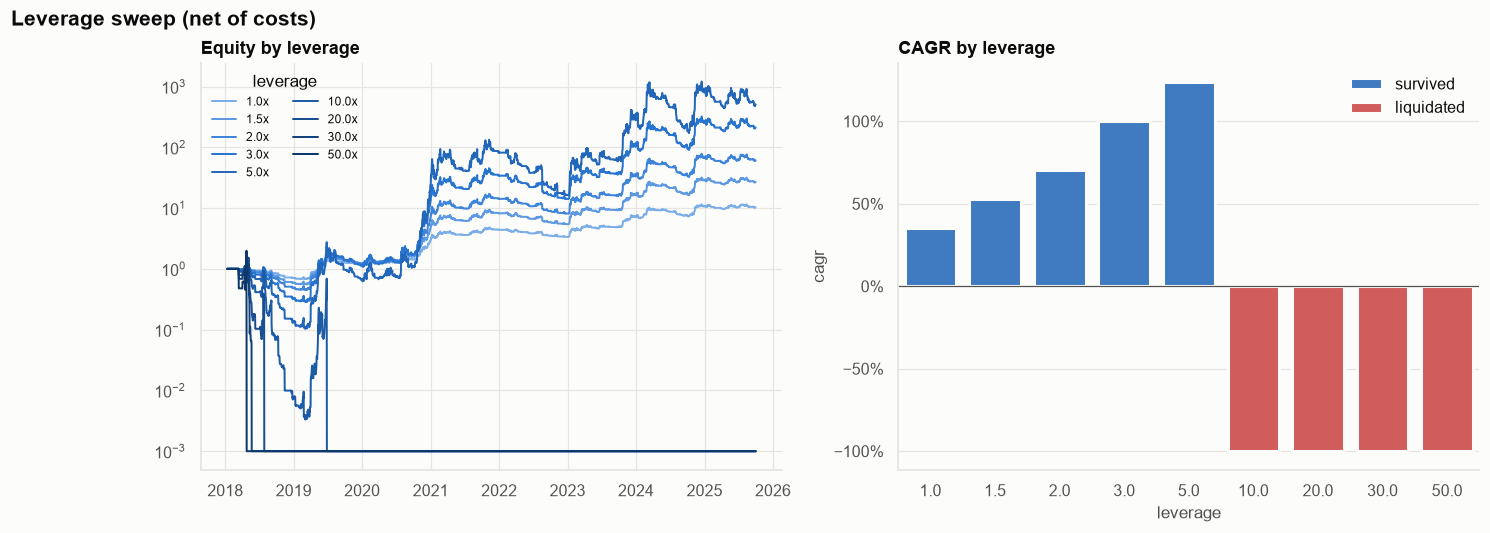

In [19]:
lev = leverage_sweep(df, signal, BEST, PERP_BY['BTC'], levels=(1, 1.5, 2, 3, 5, 10, 20, 30, 50))
plot_leverage(lev);
lev[['total_return', 'cagr', 'sharpe', 'max_dd', 'liquidated', 'liquidated_at']]

## Robustness across coins - net (spot) walk-forward OOS, same GRID
Each coin re-optimized on its own data every fold. SOL OOS starts 2022-07.

In [20]:
WF_G, WF_N, WF_P = {'BTC': wf}, {'BTC': wf_net}, {}
for c in COINS[1:]:
    WF_G[c] = walk_forward(DATA[c], signal, GRID, n_chunks=10, train_chunks=3)
    WF_N[c] = walk_forward(DATA[c], signal, GRID, n_chunks=10, train_chunks=3, costs=SPOT)
for c in COINS:
    WF_P[c] = walk_forward(DATA[c], signal, GRID, n_chunks=10, train_chunks=3, costs=PERP_BY[c])
rob = pd.DataFrame({c: {'oos_start': w.returns.index[0].date(), 'gross_sharpe': WF_G[c].metrics['sharpe'],
                        'net_sharpe': w.metrics['sharpe'], 'perp_net_sharpe': WF_P[c].metrics['sharpe'], 'bh_sharpe': w.bh_metrics['sharpe'],
                        'net_cagr': w.metrics['cagr'], 'bh_cagr': w.bh_metrics['cagr'],
                        'net_max_dd': w.metrics['max_dd'], 'bh_max_dd': w.bh_metrics['max_dd'],
                        'wf_eff': w.metrics['wf_efficiency'], 'folds_profitable': w.metrics['pct_folds_profitable'],
                        'exposure': w.metrics['exposure'], 'entries_per_yr': entries_per_year(w.position),
                        'turnover_per_yr': w.metrics['turnover_per_year']} for c, w in WF_N.items()}).T
rob

,oos_start,gross_sharpe,net_sharpe,perp_net_sharpe,bh_sharpe,net_cagr,bh_cagr,net_max_dd,bh_max_dd,wf_eff,folds_profitable,exposure,entries_per_yr,turnover_per_yr
BTC,2020-05-06,1.618424,1.531388,1.428603,1.122325,0.462291,0.629678,-0.300388,-0.75599,0.731719,0.714286,0.780142,14.432371,20.946418
ETH,2020-05-06,1.402258,1.362009,1.266491,1.112858,0.446161,0.765332,-0.24166,-0.785505,0.787969,0.571429,0.736575,9.621581,12.944683
XRP,2020-05-06,1.108699,1.089922,1.037899,0.940816,0.362826,0.596731,-0.2484,-0.826045,0.87072,0.714286,0.776596,13.137158,14.017736
LTC,2020-05-06,0.413646,0.303628,0.225487,0.62535,0.047266,0.175733,-0.53566,-0.885089,0.179588,0.428571,0.730496,12.952128,16.85403
SOL,2022-04-01,1.049759,0.99777,0.941527,0.626227,0.285447,0.137779,-0.281797,-0.927863,0.228965,0.714286,0.756841,14.278733,13.732379


### Fold-parameter table (chosen params per fold) - how stable is the choice?
S0002's weakness was L jumping between 14 and 56. Here: `alpha / NS / tv / band` per fold.

In [21]:
def _fmt(r):
    return f"a={r.alpha:g} NS={'-'.join(map(str, r.NS))} tv={r.tv:g} b={r.band:g}"
FP = pd.DataFrame({c: w.folds.set_index('fold').apply(_fmt, axis=1) for c, w in WF_N.items()})
display(FP)
stab = pd.DataFrame({c: {'folds': len(w.folds),
                         'distinct_param_sets': w.folds[['alpha', 'NS', 'tv', 'band']].astype(str).agg('|'.join, axis=1).nunique(),
                         'alpha_values': sorted(w.folds.alpha.unique().tolist()),
                         'NS_values': sorted({'-'.join(map(str, x)) for x in w.folds.NS}),
                         'tv_values': sorted(w.folds.tv.unique().tolist()),
                         'band_values': sorted(w.folds.band.unique().tolist())} for c, w in WF_N.items()}).T
stab

,BTC,ETH,XRP,LTC,SOL
fold,,,,,
1,a=1 NS=10-20-55-120 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.03 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0.1
2,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.03 b=0.1
3,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.02 b=0.1,a=0.5 NS=10-20-55-120 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.02 b=0,a=0.5 NS=10-20-55-120 tv=0.03 b=0.1
4,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0,a=1 NS=10-20-55-120 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.03 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0
5,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.03 b=0,a=1 NS=10-20-55-120 tv=0.03 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.02 b=0
6,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=20-55-120-250 tv=0.02 b=0,a=0 NS=20-55-120-250 tv=0.02 b=0
7,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=0 NS=20-55-120-250 tv=0.02 b=0.1,a=1 NS=10-20-55-120 tv=0.02 b=0.1,a=0.5 NS=10-20-55-120 tv=0.03 b=0.1


,folds,distinct_param_sets,alpha_values,NS_values,tv_values,band_values
BTC,7,2,"[0.0, 1.0]","[10-20-55-120, 20-55-120-250]",[0.02],[0.1]
ETH,7,6,"[0.0, 1.0]","[10-20-55-120, 20-55-120-250]","[0.02, 0.03]","[0.0, 0.1]"
XRP,7,5,"[0.0, 0.5, 1.0]","[10-20-55-120, 20-55-120-250]","[0.02, 0.03]","[0.0, 0.1]"
LTC,7,5,"[0.0, 1.0]","[10-20-55-120, 20-55-120-250]","[0.02, 0.03]","[0.0, 0.1]"
SOL,7,4,"[0.0, 0.5, 1.0]","[10-20-55-120, 20-55-120-250]","[0.02, 0.03]","[0.0, 0.1]"


## Deployable portfolio - equal weight of the 5 coins' net (spot) WF OOS returns
Daily average over coins live on that date (SOL joins 2022-07). Benchmark = equal-weight buy & hold, same coins and dates.

,portfolio_gross,portfolio_net_spot,portfolio_net_perp,ew_buy_hold
total_return,4.843,4.251,3.658,16.257
cagr,0.386,0.359,0.329,0.694
ann_vol,0.239,0.237,0.238,0.736
sharpe,1.486,1.413,1.316,1.087
sortino,1.979,1.888,1.752,1.484
max_dd,-0.265,-0.269,-0.265,-0.799
calmar,1.457,1.333,1.242,0.869
bars,1974.000,1974.000,1974.000,1974.000
avg_gross_exposure,0.294,0.294,0.294,1.000
ann_mean_return,0.355,0.335,0.313,0.799


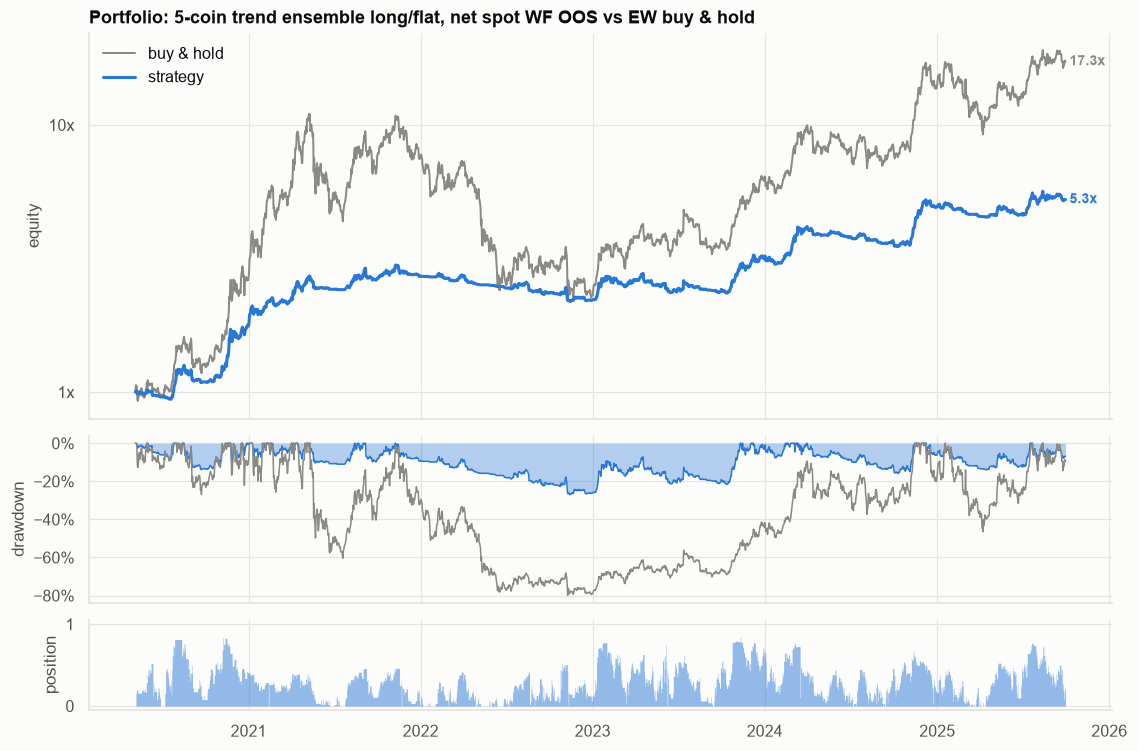

In [22]:
def port_of(WF, attr='returns'):
    R = pd.DataFrame({c: getattr(w, attr) for c, w in WF.items()})
    s = R.mean(axis=1, skipna=True); s.iloc[0] = 0.0
    return s
port_net, port_gross, port_perp = port_of(WF_N), port_of(WF_G), port_of(WF_P)
port_bh = port_of(WF_N, 'bh_returns')
port_pos = pd.DataFrame({c: w.position for c, w in WF_N.items()}).mean(axis=1, skipna=True)
PORT = SimpleNamespace(equity=(1 + port_net).cumprod(), bh_equity=(1 + port_bh).cumprod(), position=port_pos)
plot_result(PORT, 'Portfolio: 5-coin trend ensemble long/flat, net spot WF OOS vs EW buy & hold');
pm = pd.DataFrame({'portfolio_gross': metrics(port_gross), 'portfolio_net_spot': metrics(port_net),
                   'portfolio_net_perp': metrics(port_perp), 'ew_buy_hold': metrics(port_bh)})
pm.loc['avg_gross_exposure'] = [port_pos.mean()] * 3 + [1.0]
pm.loc['ann_mean_return'] = [port_gross.mean() * 365, port_net.mean() * 365, port_perp.mean() * 365, port_bh.mean() * 365]
pm.round(3)

,value
"VaR 95% (loss, <0 = gain)",-0.900
CVaR 95%,-0.510
VaR 99%,-0.278
CVaR 99%,-0.057
median total return,4.357
mean total return,5.826
P(loss),0.004
median max DD,-0.248
95th pct max DD,-0.390
99th pct max DD,-0.463


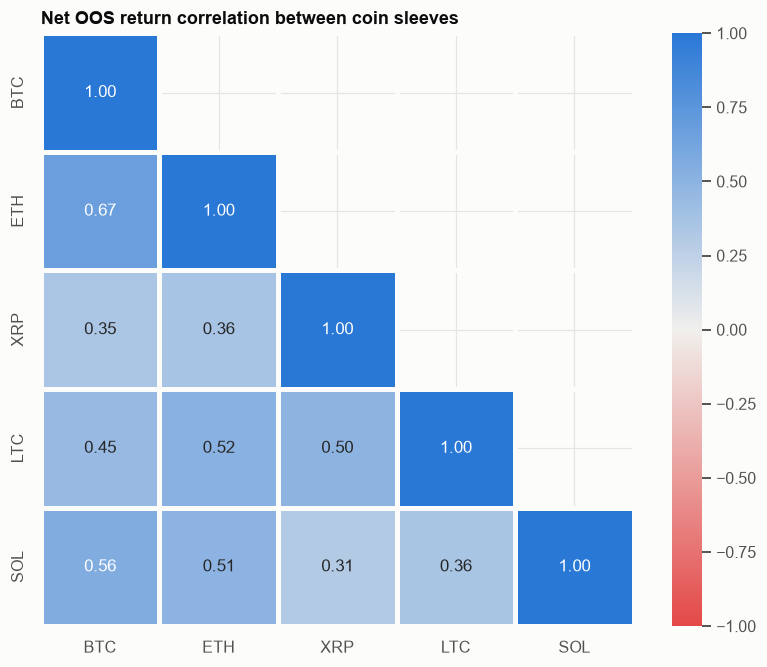

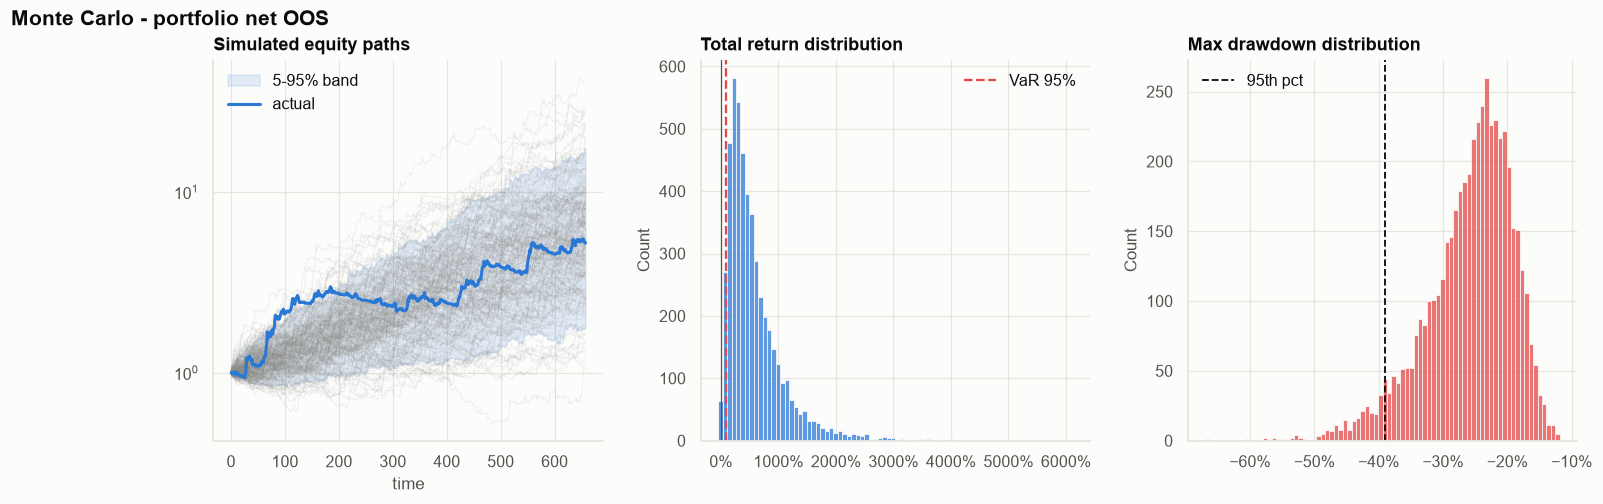

In [23]:
plot_corr(pd.DataFrame({c: w.returns for c, w in WF_N.items()}).dropna(), 'Net OOS return correlation between coin sleeves');
mc_port = monte_carlo(port_net, n=5000, method='block', block=20)
mc_port.plot('Monte Carlo - portfolio net OOS');
mc_port.table.round(3)

## Mandatory comparison vs S0002 (saved OOS) - correlation, sub-periods, 50/50 blend
S0002's saved file is its **perp-net** portfolio (fees + real funding). S0004 is shown on spot costs (primary) and perp costs (like-for-like).

In [24]:
s002 = pd.read_parquet(RESULTS_DIR / 'S0002_oos.parquet')['ret']
J = pd.DataFrame({'S0004_spot': port_net, 'S0004_perp': port_perp, 'S0002': s002, 'EW_BH': port_bh}).dropna()
print('common window:', J.index[0].date(), '->', J.index[-1].date(), len(J), 'days')
corr = pd.DataFrame({'full': {k: J['S0004_spot'].corr(J[k]) for k in ['S0002', 'EW_BH']},
                     '2022+': {k: J.loc['2022':, 'S0004_spot'].corr(J.loc['2022':, k]) for k in ['S0002', 'EW_BH']},
                     '2025+': {k: J.loc['2025':, 'S0004_spot'].corr(J.loc['2025':, k]) for k in ['S0002', 'EW_BH']}})
corr.loc['S0002 vs S0004_perp'] = [J['S0004_perp'].corr(J['S0002']), J.loc['2022':, 'S0004_perp'].corr(J.loc['2022':, 'S0002']), J.loc['2025':, 'S0004_perp'].corr(J.loc['2025':, 'S0002'])]
corr.round(3)

common window: 2020-05-06 -> 2025-09-30 1974 days


,full,2022+,2025+
S0002,0.956,0.949,0.958
EW_BH,0.778,0.750,0.743
S0002 vs S0004_perp,0.956,0.949,0.959


In [25]:
J['BLEND_spot'] = 0.5 * J['S0002'] + 0.5 * J['S0004_spot']
J['BLEND_perp'] = 0.5 * J['S0002'] + 0.5 * J['S0004_perp']
WIN = {'full OOS': (None, None), '2022+': ('2022-01-01', None), '2025+': ('2025-01-01', None)}
rows = {}
for wn, (a, b) in WIN.items():
    for col in ['S0004_spot', 'S0004_perp', 'S0002', 'BLEND_spot', 'BLEND_perp', 'EW_BH']:
        m = metrics(J[col].loc[a:b])
        rows[(wn, col)] = {'sharpe': m['sharpe'], 'cagr': m['cagr'], 'ann_vol': m['ann_vol'], 'max_dd': m['max_dd'], 'calmar': m['calmar']}
SUBT = pd.DataFrame(rows).T
SUBT.round(3)

sharpe   cagr  ann_vol  max_dd  calmar
full OOS S0004_spot   1.413  0.359    0.237  -0.269   1.333
         S0004_perp   1.316  0.329    0.238  -0.265   1.242
         S0002        1.437  0.521    0.330  -0.394   1.323
         BLEND_spot   1.443  0.441    0.280  -0.333   1.322
         BLEND_perp   1.401  0.425    0.281  -0.331   1.281
         EW_BH        1.087  0.694    0.736  -0.799   0.869
2022+    S0004_spot   0.960  0.193    0.206  -0.215   0.899
         S0004_perp   0.847  0.167    0.207  -0.211   0.790
         S0002        1.049  0.310    0.299  -0.306   1.013
         BLEND_spot   1.025  0.252    0.250  -0.261   0.968
         BLEND_perp   0.978  0.238    0.250  -0.259   0.921
         EW_BH        0.668  0.249    0.650  -0.714   0.349
2025+    S0004_spot   0.538  0.090    0.195  -0.117   0.769
         S0004_perp   0.484  0.078    0.195  -0.116   0.675
         S0002        0.549  0.124    0.290  -0.167   0.747
         BLEND_spot   0.550  0.109    0.240  -0.137   0.794
         BLEND_perp   0.528  0.103    0.240  -0.137   0.754
         EW_BH        0.788  0.352    0.649  -0.465   0.757

In [26]:
# calendar sub-periods, S0004 spot vs S0002 vs EW BH (net Sharpe / max DD)
PERIODS = {'2020-08..2021': ('2020-08', '2021-12'), '2022': ('2022-01', '2022-12'), '2023-2024': ('2023-01', '2024-12'), '2025+': ('2025-01', None)}
sp = {}
for name, (a, b) in PERIODS.items():
    sp[name] = {f'{k}_{m_}': metrics(J[k].loc[a:b])[m_] for k in ['S0004_spot', 'S0002', 'EW_BH'] for m_ in ['sharpe', 'max_dd']}
pd.DataFrame(sp).T.round(3)

,S0004_spot_sharpe,S0004_spot_max_dd,S0002_sharpe,S0002_max_dd,EW_BH_sharpe,EW_BH_max_dd
2020-08..2021,2.163,-0.139,2.121,-0.177,1.749,-0.604
2022,-1.426,-0.215,-1.203,-0.306,-1.084,-0.714
2023-2024,1.817,-0.159,1.973,-0.184,1.873,-0.318
2025+,0.538,-0.117,0.549,-0.167,0.788,-0.465


In [27]:
# Monte Carlo on the same footing: S0004 spot/perp, S0002, 50/50 blend (block bootstrap of common-window OOS returns, 5000)
MCS = {col: monte_carlo(J[col], n=5000, method='block', block=20).table for col in ['S0004_spot', 'S0004_perp', 'S0002', 'BLEND_spot']}
mc_cmp = pd.concat(MCS, axis=1)
mc_cmp.round(3)

,S0004_spot,S0004_perp,S0002,BLEND_spot
,value,value,value,value
"VaR 95% (loss, <0 = gain)",-0.900,-0.705,-1.444,-1.166
CVaR 95%,-0.510,-0.361,-0.791,-0.678
VaR 99%,-0.278,-0.153,-0.402,-0.374
CVaR 99%,-0.057,0.043,-0.082,-0.090
median total return,4.357,3.731,8.893,6.313
mean total return,5.826,5.009,14.378,9.240
P(loss),0.004,0.005,0.003,0.003
median max DD,-0.248,-0.255,-0.326,-0.283
95th pct max DD,-0.390,-0.405,-0.498,-0.437


## Implementation check: cost drag (BTC, best params, full history)

In [28]:
TRADE_ONLY = CostModel.okx_perp(funding_rate_8h=0.0)
runs = {'gross': run(df, signal, BEST), 'spot costs': run(df, signal, BEST, costs=SPOT),
        'perp trading only': run(df, signal, BEST, costs=TRADE_ONLY), 'perp net (real funding)': run(df, signal, BEST, costs=PERP_BY['BTC'])}
drag = pd.DataFrame({k: {'ann_return': r.returns.mean() * 365, 'cagr': r.metrics['cagr'], 'sharpe': r.metrics['sharpe'],
                         'turnover_per_year': r.metrics['turnover_per_year']} for k, r in runs.items()}).T
drag['drag_vs_gross_ann'] = drag.ann_return['gross'] - drag.ann_return
drag.round(4)

,ann_return,cagr,sharpe,turnover_per_year,drag_vs_gross_ann
gross,0.3885,0.4218,1.4244,19.6964,0.0000
spot costs,0.3658,0.3899,1.3414,19.6964,0.0226
perp trading only,0.3757,0.4037,1.3775,19.6964,0.0128
perp net (real funding),0.3388,0.3530,1.2435,19.6964,0.0496


### Live parameters now (each coin re-optimized on its most recent 30% of history, spot net)

In [29]:
LIVE = {}
for c in COINS:
    d = DATA[c]; start = d.index[int(len(d) * 0.7)]
    t = grid_search(d, signal, GRID, costs=SPOT, start=start)
    bp = best_params(t, GRID)
    sg = np.log(d.close).diff().rolling(60).std().iloc[-1]
    LIVE[c] = {**{k: ('-'.join(map(str, v)) if k == 'NS' else v) for k, v in bp.items()}, 'train_from': start.date(),
               'sigma60_d': sg, 'target_pos_now': signal(d, bp).iloc[-1], 'as_of': d.index[-1].date()}
pd.DataFrame(LIVE).T

,alpha,NS,tv,band,train_from,sigma60_d,target_pos_now,as_of
BTC,0.0,20-55-120-250,0.02,0.1,2023-06-07,0.015985,0.333333,2025-09-30
ETH,0.5,10-20-55-120,0.02,0.1,2023-06-07,0.037529,0.157126,2025-09-30
XRP,0.0,20-55-120-250,0.02,0.1,2023-06-07,0.033229,0.0,2025-09-30
LTC,0.0,20-55-120-250,0.02,0.1,2023-06-07,0.03259,0.0,2025-09-30
SOL,1.0,10-20-55-120,0.02,0.1,2024-04-01,0.040886,0.121669,2025-09-30


### Save portfolio net (spot) OOS returns

In [30]:
save_oos(META['id'], port_net)

PosixPath('results/S0004_oos.parquet')

**Verdict: VIABLE (5-coin equal-weight, spot, 1x) - but a replacement/blend candidate for S0002, not an additional deployable (corr 0.96). Numbers are from the locked-data re-execution (OOS 2020-05 -> 2025-09-30). GATE FLAG: the 1-year MC95 max DD is -26.0% vs the -25% limit, a marginal fail; Sharpe and CAGR legs pass. Status left as viable.**

| Check | Result | Pass? |
|---|---|---|
| Plateau, not spike (BTC IS) | top-12 smoothed Sharpe 1.57-1.60 across alpha 0/0.5, both NS, both tv | yes |
| DSR > 0.95 (BTC IS, 24 trials) | 0.999 (IS Sharpe 1.65 vs SR0 0.13; notebook-local count) | yes |
| WF efficiency > 0.5 (BTC net) | 0.73, 5/7 folds profitable; ETH 0.79, XRP 0.87, LTC 0.18, SOL 0.23 | BTC, ETH, XRP yes; LTC, SOL no |
| Permutation p < 0.05, fixed params (BTC IS, 2000) | gross 0.002, net 0.0025 | yes |
| Permutation p, re-optimized GRID, net, n=300 | BTC IS 0.010, **BTC 2nd half 0.023**, ETH IS 0.007, **ETH 2nd half 0.073** | BTC yes; ETH 2nd half fails (S0002 also failed its 2nd half) |
| Edge survives costs (BTC net WF OOS) | Sharpe 1.53 vs BH 1.12, CAGR 46.2% vs 63.0%, max DD -30% vs -76% | yes (risk-adjusted) |
| Other coins net WF Sharpe vs BH | ETH 1.36 vs 1.11, XRP 1.09 vs 0.94, SOL 1.00 vs 0.63, LTC 0.30 vs 0.63 | 3/4 |
| Portfolio net WF OOS | Sharpe 1.41 vs EW BH 1.09, CAGR 35.9% vs 69.4%, max DD -26.9% vs -79.9%, vol 24% | yes |
| Sub-periods | 2022+ Sharpe 0.96 vs BH 0.67 (S0002 1.05); 2025+ 0.54 vs 0.79 (S0002 0.55); 2022 -1.43 (S0002 -1.20) | yes for 2022+, 2025+ lags buy and hold |
| MC 95th-pct max DD | full path portfolio -39% (S0002 -50%, blend -44%), BTC -42%; 1-year horizon -26.0% | full path tolerable at 1x; 1-year **marginal fail vs -25%** |
| Paper-trade gate | Sharpe 1.41 pass, CAGR 35.9% pass, 1-year MC95 DD -26.0% **fail (by 1 point)** | flagged |
| Cost drag | BTC spot 2.3%/yr (perp incl. funding 5.0%/yr); portfolio spot 2.0%/yr | ok |
| Sensible leverage | 1x; 1.5x DD -48%; 10x+ liquidated | 1x |
| Fold-parameter stability | BTC 2 distinct param sets in 7 folds (alpha 0 in 6/7), ETH 6, XRP 5, LTC 5, SOL 4; S0002 L jumped 14 <-> 56 | better than S0002 for BTC only |

**S0002 decision rule (corr 0.96 > 0.8 -> replacement candidate).** Correlation with S0002 net OOS: 0.96 full, 0.95 since 2022, 0.96 since 2025 (EW buy & hold 0.78). Like-for-like on the common window 2020-05-06 -> 2025-09-30 (S0002 file is perp-net; S0004 shown spot and perp):

| window | S0004 spot | S0004 perp | S0002 (perp) | 50/50 blend (spot) |
|---|---|---|---|---|
| Sharpe full | 1.41 | 1.32 | 1.44 | 1.44 |
| Sharpe 2022+ | 0.96 | 0.85 | 1.05 | 1.03 |
| Sharpe 2025+ | 0.54 | 0.48 | 0.55 | 0.55 |
| CAGR full | 35.9% | 32.9% | 52.1% | 44.1% |
| Max DD full | -26.9% | -26.5% | -39.4% | -33.3% |
| MC 95% max DD (full path) | **-39%** | -41% | -50% | -44% |

S0002 has the slightly higher Sharpe in every window, S0004 wins drawdown and MC tail (mostly because it runs at lower risk: average exposure 29% vs about 41%, and the Sharpe difference is statistically indistinguishable). There is no clear winner, so the lowest-regret choice is the **50/50 blend** (full Sharpe 1.44, DD and MC tail between the two) or keeping S0002 on spot; stacking both adds no diversification.

**Caveats:** the optimizer almost always chose alpha = 0 for BTC, so what survives is the 14/28/56 TSMOM ensemble with band 0.1 and tv 0.02; the Donchian leg (H0012's main idea) adds little in this grid. For alpha = 0 the NS value is irrelevant and ties resolve to the first NS in the grid (a display artifact in the fold table). Permutation re-optimization uses n=300 (min p 0.003). OOS starts 2020-05 (portfolio 2020-08), the 2020-21 bull drives much of the total; survivorship (today's five coins); LTC does not work; S0002 comparison mixes perp-net (S0002 file) with spot-net (S0004) so perp rows are provided; the 5-coin portfolio is one BTC factor.
